# Preprocessing Sentinel-1 Myself
Disclaimer: for portions of this code, I consulted Claude to help understand why my images weren't lining up with the USGS data. It was taking way too long to work through this myself to rescue just 12 points, so this felt like a reasonable use of AI.

Parts of the June 10th radar image were unreadable (notebook 01), so here I rebuild that scene from the raw Sentinel-1 data, copying the USGS processing as closely as I can. It's also a test of whether I can make these images myself, which I'd need to do to run the model anywhere USGS hasn't (e.g. beyond this stretch of the Madeira).

The USGS metadata lists what they did step by step. They downloaded the raw GRD products from the Alaska Satellite Facility and ran them through ESA's SNAP software, which applies the precise orbit file, removes thermal and border noise, calibrates to sigma0 (backscatter per unit ground area), and terrain-corrects onto a map. They chose not to speckle filter, since that can wash out small objects like dredges. Four dates needed two scenes mosaicked together, and everything was clipped to the river between Porto Velho and Abunã. The output is linear sigma0 on a lat/lon grid w/ 10m pixels.

I don't have SNAP and I wanted something that runs in plain Python, so my version differs in one place. I do the calibration and noise removal from the lookup tables that come with each product, then place the image on the map with the product's own ground control points. SNAP uses an elevation model for that last step; the area is flat floodplain, so at first I guessed I could skip it, but it turns out I need one too (added further down). Then I write out a replacement for the corrupt June 10th file and check the labels on it.

The first step was finding the same raw products. USGS lists the 11 product names in `Scene_Names.csv`, and Microsoft's Planetary Computer hosts the full Sentinel-1 GRD archive with no login needed, so I looked each one up there.

In [1]:
import xml.etree.ElementTree as ET
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import planetary_computer
import pyproj
import pystac_client
import rasterio
import requests
from rasterio.control import GroundControlPoint
from rasterio.transform import Affine
from rasterio.warp import Resampling, reproject
from rasterio.windows import Window
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator
from scipy.ndimage import map_coordinates
from skimage.registration import phase_cross_correlation

from helpers import PROC, RAW, db, load_points

USGS = {d: RAW / "sar" / f"S1{s}_IW_GRDH_1SDV_2019{d}.tif" for s, d in [("A", "0604"), ("B", "0610")]}
with rasterio.open(USGS["0604"]) as src:
    grid = dict(crs=src.crs, transform=src.transform, width=src.width, height=src.height)  # the grid i want to match
H, W, T = grid["height"], grid["width"], grid["transform"]
west, south, east, north = rasterio.transform.array_bounds(H, W, T)

# planetary computer signs the storage urls, so they can be read without a login
catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)
scenes = pd.read_csv(RAW / "sar" / "Scene_Names.csv", encoding="utf-8-sig")
# planetary computer ids drop the last 5 characters of the product name, but the full name shows up in the file path
scenes["item_id"] = scenes["Scene Name"].str[:-5]
items = {i.id: i for i in catalog.search(collections=["sentinel-1-grd"], ids=list(scenes["item_id"])).items()}
scenes["found"] = [i in items and name in items[i].assets["vv"].href for i, name in zip(scenes["item_id"], scenes["Scene Name"])]
scenes[["Date", "Scene Name", "found"]]

,Date,Scene Name,found
0,6/4/2019,S1A_IW_GRDH_1SDV_20190604T095712_20190604T0957...,True
1,6/4/2019,S1A_IW_GRDH_1SDV_20190604T095737_20190604T0957...,True
2,6/10/2019,S1B_IW_GRDH_1SDV_20190610T095642_20190610T0957...,True
3,6/16/2019,S1A_IW_GRDH_1SDV_20190616T095737_20190616T0957...,True
4,6/16/2019,S1A_IW_GRDH_1SDV_20190616T095712_20190616T0957...,True
5,6/22/2019,S1B_IW_GRDH_1SDV_20190622T095642_20190622T0957...,True
6,6/28/2019,S1A_IW_GRDH_1SDV_20190628T095738_20190628T0958...,True
7,6/28/2019,S1A_IW_GRDH_1SDV_20190628T095713_20190628T0957...,True
8,7/4/2019,S1B_IW_GRDH_1SDV_20190704T095643_20190704T0957...,True
9,7/10/2019,S1A_IW_GRDH_1SDV_20190710T095739_20190710T0958...,True


All 11 are there. The raw GRD image isn't backscatter yet. Each pixel is a digital number (DN) from the instrument, laid out in radar geometry; rows follow the satellite's path and columns follow the distance from it, so the image isn't on a map yet. Each product comes with two lookup tables that turn DNs into sigma0:

- a **calibration table**, which scales DN² into backscatter, and
- a **noise table**, an estimate of the instrument's own thermal noise. This matters most over dark surfaces like water, where noise can be a big share of the signal.

Both tables are on a coarse grid (every 40 columns and every few hundred rows), so I interpolate them to every pixel and compute sigma0 = (DN² − noise) / calibration², setting negative values to zero like SNAP does. I only read the part of the image over the study area, which I find by running the product's ground control points in reverse.

I start with June 10th since it's a single scene that covers the whole area, and it's the date I need to replace. The output is still in radar geometry at this point, so I save it with its ground control points (shifted to the cropped window) for the next step. It's cached in `data/interim`, so this only downloads once.

In [2]:
INTERIM = RAW.parent / "interim" / "sigma0_radar"
INTERIM.mkdir(parents=True, exist_ok=True)


def radar_window(href, pad=200):
    """rows and columns of the raw image that cover the study area, from the product's gcps."""
    with rasterio.open(href) as src:
        gcps, height, width = src.gcps[0], src.height, src.width
    # gcps map image -> lon/lat; interpolating the other way gives image positions for the edges of the study area
    to_image = LinearNDInterpolator([(g.x, g.y) for g in gcps], [(g.row, g.col) for g in gcps])
    t = np.linspace(0, 1, 50)
    lon, lat = west + (east - west) * t, south + (north - south) * t
    edge = np.r_[np.c_[lon, np.full(50, north)], np.c_[lon, np.full(50, south)], np.c_[np.full(50, west), lat], np.c_[np.full(50, east), lat]]
    rc = to_image(edge)  # edge points outside the swath come back as nan and get ignored
    r0, c0 = np.maximum(np.floor(np.nanmin(rc, 0)) - pad, 0).astype(int)
    r1, c1 = np.minimum(np.ceil(np.nanmax(rc, 0)) + pad, [height, width]).astype(int)
    return Window(c0, r0, c1 - c0, r1 - r0), gcps


def interp_table(root, tag, value, rows, cols):
    """a coarse calibration or noise table, interpolated to every pixel of a block."""
    lines, vals = [], []
    for v in root.iter(tag):
        lines.append(int(v.find("line").text))
        # first along each row, since rows can list different columns
        vals.append(np.interp(cols, np.array(v.find("pixel").text.split(), float), np.array(v.find(value).text.split(), float)))
    lines, vals = np.array(lines), np.array(vals)
    # then linearly between the two nearest rows of the table
    i = np.clip(np.searchsorted(lines, rows) - 1, 0, len(lines) - 2)
    f = ((rows - lines[i]) / (lines[i + 1] - lines[i]))[:, None]
    return (vals[i] * (1 - f) + vals[i + 1] * f).astype(np.float32)


def azimuth_noise(root, rows, cols):
    """noise also changes along the path, in separate blocks for each sub-swath."""
    out = np.ones((len(rows), len(cols)), np.float32)
    for b in root.iter("noiseAzimuthVector"):
        get = lambda k: int(b.find(k).text)
        in_rows = (rows >= get("firstAzimuthLine")) & (rows <= get("lastAzimuthLine"))
        in_cols = (cols >= get("firstRangeSample")) & (cols <= get("lastRangeSample"))
        if in_rows.any() and in_cols.any():
            lut = np.interp(rows[in_rows], np.array(b.find("line").text.split(), float), np.array(b.find("noiseAzimuthLut").text.split(), float))
            out[np.ix_(in_rows, in_cols)] = lut[:, None]
    return out


def sigma0_strip(href, cal, noise, win, row0, nrows):
    """one strip of dns, turned into sigma0."""
    with rasterio.open(href) as src:
        dn = src.read(1, window=Window(win.col_off, row0, win.width, nrows)).astype(np.float32)
    rows, cols = np.arange(row0, row0 + nrows), np.arange(win.col_off, win.col_off + win.width)
    a = interp_table(cal, "calibrationVector", "sigmaNought", rows, cols)
    n = interp_table(noise, "noiseRangeVector", "noiseRangeLut", rows, cols) * azimuth_noise(noise, rows, cols)
    s0 = np.maximum(dn ** 2 - n, 0) / a ** 2
    s0[dn == 0] = np.nan  # dn 0 is outside the image
    return s0


def calibrate_scene(item, strip=1024):
    """sigma0 for vh and vv (the usgs band order), cropped to the study area and saved with shifted gcps."""
    out = INTERIM / f"{item.id}.tif"
    if out.exists():
        return out
    win, gcps = radar_window(item.assets["vv"].href)
    shifted = [GroundControlPoint(row=g.row - win.row_off, col=g.col - win.col_off, x=g.x, y=g.y, z=g.z) for g in gcps]
    profile = dict(driver="GTiff", dtype="float32", count=2, width=win.width, height=win.height, nodata=np.nan, tiled=True,
                   blockxsize=512, blockysize=512, compress="deflate", predictor=3, BIGTIFF="IF_SAFER", gcps=shifted,
                   crs=rasterio.crs.CRS.from_epsg(4326))
    with rasterio.open(out, "w", **profile) as dst:
        for band, pol in enumerate(["vh", "vv"], start=1):
            cal, noise = (ET.fromstring(requests.get(item.assets[f"schema-{t}-{pol}"].href).content) for t in ("calibration", "noise"))
            starts = range(win.row_off, win.row_off + win.height, strip)
            # strips download in parallel (the slow part) but get written in order
            with ThreadPoolExecutor(6) as pool:
                strips = pool.map(lambda r: sigma0_strip(item.assets[pol].href, cal, noise, win, r, min(strip, win.row_off + win.height - r)), starts)
                for r, s0 in zip(starts, strips):
                    dst.write(s0, band, window=Window(0, r - win.row_off, win.width, s0.shape[0]))
    return out


june10 = items[scenes.loc[scenes["Date"] == "6/10/2019", "item_id"].iloc[0]]
radar_path = calibrate_scene(june10)
with rasterio.open(radar_path) as src:
    print(f"{radar_path.name}: {src.width} x {src.height} px in radar geometry")

S1B_IW_GRDH_1SDV_20190610T095642_20190610T095711_016632_01F4E3.tif: 18803 x 16051 px in radar geometry


Next I put the June 10th image on the map, on the same grid as the USGS files. The simplest way is the ground control points alone; they tie a few hundred image positions to lat/lon, and GDAL bends the image to fit them w/ bilinear resampling (the SNAP default). SNAP does more than this, though: it traces each pixel back to the satellite's orbit and an elevation model, so position is where I'd expect the two versions to differ.

So I compare my image with USGS in two ways. For brightness, I take the difference in dB, pixel by pixel, over water and over land, using the readable tiles of the USGS June 10th file. For position, the corrupt tiles left too few clean windows in the June 10th file, so I measure against the USGS June 4th image instead. I cut the images into 1536-pixel windows that include some river and measure how far mine is shifted in each one. As a yardstick, I do the same for the readable USGS June 10th windows, which came out of SNAP just like June 4th.

In [3]:
def read_usgs(path, band=2):
    """one usgs band, tile by tile; corrupt tiles and nodata come back as nan."""
    with rasterio.open(path) as src:
        out = np.full((src.height, src.width), np.nan, np.float32)
        for _, w in src.block_windows(band):
            try:
                out[w.toslices()] = src.read(band, window=w)
            except Exception:
                pass
    out[out > 1e30] = np.nan
    return out


def geocode_gcp(radar_path, band=2):
    """one band warped onto the usgs grid using only the product's gcps."""
    with rasterio.open(radar_path) as src:
        dst = np.full((H, W), np.nan, np.float32)
        reproject(src.read(band), dst, gcps=src.gcps[0], src_crs=src.gcps[1], dst_crs=grid["crs"], dst_transform=T, src_nodata=np.nan,
                  dst_nodata=np.nan, resampling=Resampling.bilinear, SRC_METHOD="GCP_TPS", num_threads=4)
    return dst


def brightness_diff(mine, usgs):
    """median and middle 50% of the db difference, over water (below -15 db, about notebook 02's otsu cutoffs) and land."""
    both = np.isfinite(mine) & np.isfinite(usgs)
    diff, water = mine[both] - usgs[both], usgs[both] < -15
    return pd.DataFrame({name: {"pixels": m.sum(), "median diff (dB)": round(float(np.median(diff[m])), 2),
                                "middle 50% of diffs (dB)": np.round(np.percentile(diff[m], [25, 75]), 2)}
                         for name, m in [("water", water), ("land", ~water)]}).T


def window_shifts(ref, moving, size=1536):
    """how far `moving` sits from `ref` (meters) in each half-overlapping window with some river (edges to line up)."""
    out = []
    for r0 in range(0, H - size, size // 2):
        for c0 in range(0, W - size, size // 2):
            a, b = ref[r0:r0 + size, c0:c0 + size], moving[r0:r0 + size, c0:c0 + size]
            ok = np.isfinite(a) & np.isfinite(b)
            if np.mean(a < -15) < 0.03:
                continue
            if ok.mean() < 0.9:  # too much missing to trust
                out.append((r0 + size // 2, c0 + size // 2, np.nan, np.nan))
                continue
            # fill the gaps, and clip so bright speckle doesn't swamp the river edges
            fill = np.median(a[ok])
            a, b = (np.clip(np.where(ok, x, fill), -22, -5) for x in (a, b))
            out.append((r0 + size // 2, c0 + size // 2, *phase_cross_correlation(a, b, upsample_factor=10)[0]))
    out = pd.DataFrame(out, columns=["row", "col", "dy", "dx"])
    return 10 * np.hypot(out["dy"], out["dx"])  # pixels are 10m


vv_usgs, vv_usgs_jun4, vv_gcp = db(read_usgs(USGS["0610"])), db(read_usgs(USGS["0604"])), db(geocode_gcp(radar_path))
lost = np.isnan(vv_usgs) & np.isfinite(vv_usgs_jun4)  # usgs june 10 pixels lost to corrupt tiles, inside the area june 4 covers
print(f"unreadable usgs june 10 pixels: {lost.sum():,}, share mine fills: {np.isfinite(vv_gcp[lost]).mean():.2%}")
display(brightness_diff(vv_gcp, vv_usgs))

shifts = pd.DataFrame({"mine, gcps only": window_shifts(vv_usgs_jun4, vv_gcp), "usgs jun 10": window_shifts(vv_usgs_jun4, vv_usgs)})
shifts.describe().loc[["count", "50%", "max"]].round(1).rename(index={"50%": "median (m)", "max": "max (m)"})

unreadable usgs june 10 pixels: 11,248,849, share mine fills: 100.00%


,pixels,median diff (dB),middle 50% of diffs (dB)
water,4655532,0.28,"[-1.93, 2.62]"
land,45017329,-0.01,"[-1.4, 1.37]"


,"mine, gcps only",usgs jun 10
count,47.0,18.0
median (m),6.1,5.7
max (m),41.0,7.1


Brightness matches USGS almost exactly over land and is a little brighter over water, which is where noise removal matters most. My image also covers every pixel the corrupt tiles knock out of the USGS file. Position ends up being the problem. Near Porto Velho my image lines up with USGS, but toward Abunã it drifts two to four pixels east-west, which is a lot when notebook 01 matches points within 30m. The USGS June 10th image sits within a pixel of June 4th everywhere, so the drift is in my version.

My guess was ground height. The ground control points assume one smooth height surface, but a radar measures distance, so ground that's higher than assumed shows up closer to the satellite (a smaller column in the raw image) by height difference / tan(incidence angle). SNAP corrects for this with an elevation model, and the gcps-only version doesn't. So I add that correction myself:

1. Every 8 pixels (80m) of the output grid, I interpolate the product's geolocation grid to get the raw image row and column, the height the grid assumed, and the incidence angle.
2. I get the real height there from the Copernicus 30m elevation model (also free on Planetary Computer), converted from height above sea level to height above the ellipsoid, which is what Sentinel-1 uses.
3. I move each column by the height difference / tan(incidence angle) / 10m, then interpolate the coarse grid to every pixel and sample the raw image bilinearly.

In [4]:
NODE = 8  # work out the mapping every 8 pixels and interpolate between
node_rows, node_cols = np.meshgrid(np.arange(H // NODE + 2) * NODE, np.arange(W // NODE + 2) * NODE, indexing="ij")
node_lon, node_lat = T.c + (node_cols + 0.5) * T.a, T.f + (node_rows + 0.5) * T.e


def dem_heights():
    """copernicus glo-30 heights at every node, as heights above the wgs84 ellipsoid."""
    dem = np.full(node_lon.shape, np.nan, np.float32)
    # a coarse grid whose cell centers sit on the node pixels
    node_grid = Affine(T.a * NODE, 0, T.c + (0.5 - NODE / 2) * T.a, 0, T.e * NODE, T.f + (0.5 - NODE / 2) * T.e)
    for tile in catalog.search(collections=["cop-dem-glo-30"], bbox=[node_lon.min(), node_lat.min(), node_lon.max(), node_lat.max()]).items():
        with rasterio.open(tile.assets["data"].href) as src:
            part = np.full_like(dem, np.nan)
            reproject(rasterio.band(src, 1), part, dst_transform=node_grid, dst_crs=grid["crs"], dst_nodata=np.nan, resampling=Resampling.average)
        dem = np.where(np.isfinite(part), part, dem)
    # copernicus heights are above the egm2008 geoid; pyproj downloads the geoid grid to convert
    pyproj.network.set_network_enabled(True)
    return pyproj.Transformer.from_crs("EPSG:4326+3855", "EPSG:4979", always_xy=True).transform(node_lon, node_lat, dem)[2]


def radar_coords(item, dem):
    """raw image row and column (in the cropped window) for every node, corrected for terrain height."""
    win, _ = radar_window(item.assets["vv"].href)
    root = ET.fromstring(requests.get(item.assets["schema-product-vv"].href).content)
    keys = ["line", "pixel", "latitude", "longitude", "height", "incidenceAngle"]
    geo = pd.DataFrame([{k: float(p.find(k).text) for k in keys} for p in root.iter("geolocationGridPoint")])
    fit = CloughTocher2DInterpolator(geo[["longitude", "latitude"]].values, geo[["line", "pixel", "height", "incidenceAngle"]].values)
    line, pixel, grid_height, incidence = np.moveaxis(fit(node_lon, node_lat), -1, 0)
    # ground higher than the grid assumes shows up closer to the radar, at a smaller column
    pixel = pixel - (dem - grid_height) / np.tan(np.radians(incidence)) / float(root.find(".//rangePixelSpacing").text)
    return line - win.row_off, pixel - win.col_off


def remap(radar_path, band, row_map, col_map, strip=1024):
    """one band of the raw image sampled onto the usgs grid, a strip of rows at a time."""
    with rasterio.open(radar_path) as src:
        raw = src.read(band)
    out = np.full((H, W), np.nan, np.float32)
    for r0 in range(0, H, strip):
        r1, n0 = min(H, r0 + strip), r0 // NODE
        # each pixel's position on the node grid, then bilinear between nodes
        rows, cols = np.meshgrid(np.arange(r0, r1) / NODE - n0, np.arange(W) / NODE, indexing="ij")
        src_rc = [map_coordinates(m[n0:r1 // NODE + 2], [rows, cols], order=1, mode="nearest") for m in (row_map, col_map)]
        out[r0:r1] = map_coordinates(raw, src_rc, order=1, cval=np.nan, prefilter=False)
    return out


row_map, col_map = radar_coords(june10, dem_heights())
vv_dem = db(remap(radar_path, 2, row_map, col_map))
del vv_gcp  # only its shifts are needed from here

shifts["mine, dem corrected"] = window_shifts(vv_usgs_jun4, vv_dem)
display(shifts.describe(percentiles=[0.5, 0.9]).loc[["count", "50%", "90%", "max"]].round(1)
        .rename(index={"50%": "median (m)", "90%": "90th pct (m)", "max": "max (m)"}))
display(brightness_diff(vv_dem, vv_usgs))

# border noise check: the corridor reaches the near edge of this scene, where border noise would show up
d = (vv_dem - vv_usgs)[::NODE, ::NODE]
d = d[col_map[:d.shape[0], :d.shape[1]] < 500]
print(f"within 500 columns of the image edge: {np.isfinite(d).sum():,} sampled pixels, median diff {np.nanmedian(d):.2f} dB")

,"mine, gcps only",usgs jun 10,"mine, dem corrected"
count,47.0,18.0,47.0
median (m),6.1,5.7,4.0
90th pct (m),27.3,6.6,5.8
max (m),41.0,7.1,6.3


,pixels,median diff (dB),middle 50% of diffs (dB)
water,4651967,-0.02,"[-1.12, 0.99]"
land,45016916,-0.0,"[-0.37, 0.37]"


within 500 columns of the image edge: 6,865 sampled pixels, median diff 0.01 dB


The elevation correction fixed the drift! With it, the typical window sits 4m from USGS June 4th and the worst is 6m, against 27m (90th percentile) and 41m for gcps only. That's about as close as the USGS June 10th image itself sits to June 4th (about 6m). Brightness tightens too, since the pixels now line up; the median difference is zero over land and water, and half of all land pixels are within 0.4 dB. The scene's near edge runs through the corridor at the Porto Velho end, but brightness matches there too, so I skip a separate border noise step (ESA has blanked most border noise in the products themselves since early 2018, and my code already treats those blank pixels as missing).

That's close enough to stand in for the broken USGS file. I write both bands in the USGS format (same grid, band order, tiling & nodata value), masked to the river corridor all seven USGS files share. Then I check the June 10th labels the same way notebook 01 did, with the distance from each label to the brightest VV pixel within 21×21 pixels.

wrote S1B_IW_GRDH_1SDV_20190610.tif: 900 MB


,USGS June 10,mine June 10
labels readable,26.0,32.0
"median offset (px), readable in both",1.8,1.8
"share within 2 px, readable in both",0.5,0.5


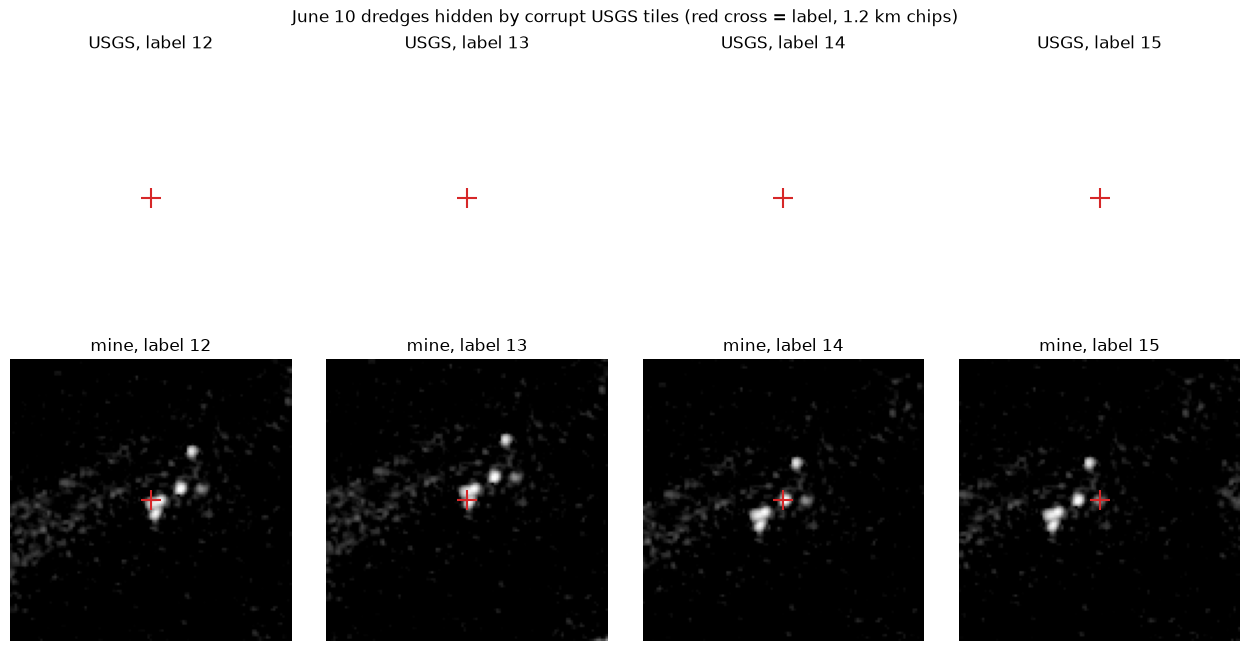

In [5]:
replacement = PROC / "sar_mine" / "S1B_IW_GRDH_1SDV_20190610.tif"
replacement.parent.mkdir(parents=True, exist_ok=True)
corridor = np.isfinite(vv_usgs_jun4)  # every usgs file covers the same corridor, so june 4's footprint is the mask
with rasterio.open(USGS["0604"]) as src:
    profile = src.profile
with rasterio.open(replacement, "w", **profile) as dst:
    for band in (1, 2):  # vh, vv
        sigma0 = remap(radar_path, band, row_map, col_map)
        dst.write(np.where(corridor & np.isfinite(sigma0), sigma0, profile["nodata"]).astype(np.float32), band)
print(f"wrote {replacement.name}: {replacement.stat().st_size / 1e6:.0f} MB")

labels = load_points("Visual", crs=grid["crs"])
labels = labels[labels["date"] == "2019-06-10"]
label_rc = np.array(rasterio.transform.rowcol(T, labels.geometry.x, labels.geometry.y)).T


def label_offsets(vv):
    """distance (px) from each label to the brightest pixel within 21 x 21; nan if the window isn't fully readable."""
    chips = [vv[r - 10:r + 11, c - 10:c + 11] for r, c in label_rc]
    return np.array([np.nan if np.isnan(c).any() else np.hypot(*np.subtract(np.unravel_index(c.argmax(), c.shape), 10)) for c in chips])


offsets = pd.DataFrame({"USGS June 10": label_offsets(vv_usgs), "mine June 10": label_offsets(vv_dem)})
in_both = offsets.dropna()
display(pd.DataFrame({"labels readable": offsets.notna().sum(), "median offset (px), readable in both": in_both.median().round(1),
                      "share within 2 px, readable in both": (in_both <= 2).mean().round(2)}).T)

# what the corrupt tiles hide: labels the usgs file can't show, next to mine
hidden = offsets.index[offsets["USGS June 10"].isna() & offsets["mine June 10"].notna()][:4]
fig, axes = plt.subplots(2, len(hidden), figsize=(3.2 * len(hidden), 6.6), squeeze=False)
for j, i in enumerate(hidden):
    r, c = label_rc[i]
    for ax, (name, vv) in zip(axes[:, j], [("USGS", vv_usgs), ("mine", vv_dem)]):
        ax.imshow(vv[r - 60:r + 61, c - 60:c + 61], cmap="gray", vmin=-22, vmax=0)
        ax.plot(60, 60, "+", color="tab:red", ms=14, mew=1.5)
        ax.set_title(f"{name}, label {i}")
        ax.axis("off")
fig.suptitle("June 10 dredges hidden by corrupt USGS tiles (red cross = label, 1.2 km chips)")
plt.tight_layout()
plt.show()

My version fills in every pixel the corrupt tiles knocked out, and all 32 June 10th labels can be read, rather than 26 in the USGS file. (Notebook 01 counted 8 unreadable labels rather than 6 because it read each window in one request, which fails for two labels whose tiles decode fine when read one at a time, like here.) On the labels both files can show, the labels sit the same distance from the brightest pixel (a median of 1.8 pixels, half within 2 pixels), so the dredges are where the labelers put them.

So `data/processed/sar_mine/S1B_IW_GRDH_1SDV_20190610.tif` can replace the corrupt USGS June 10th file. The later notebooks read June 10th from this file, which brings back 12 candidates (all of them dredges) whose windows were unreadable in the USGS version.

This also means I now have a preprocessing pipeline that runs in Python on free data, for taking the project further: raw GRD products and the Copernicus elevation model from Planetary Computer, calibration and noise removal from the product's own tables, and placement from its geolocation grid with an elevation correction. It takes about 7 minutes per scene, mostly downloading. A few things I'd still want to check before trusting it somewhere new:

- I didn't apply the precise orbit file. The product's own geolocation was good to about 6m here, but that may not hold for every scene.
- This is a check on one scene only. The other six dates still come from USGS, and I haven't run or checked the pipeline on them, including the four that need two scenes mosaicked together.